# 01 · Requisitos de Datos y Auditoría de Cartera Revolvente

## Contexto Regulatorio: Exposición al Incumplimiento (EAD) y CCF
Bajo **IFRS 9 (B5.5.30)** y **Basilea (CRE32)**, en contratos revolventes (tarjetas, sobregiros, líneas de crédito), la **Exposición al Incumplimiento (EAD)** no es fija:

$$\text{EAD}_T = \text{Saldo}_t + \text{CCF} \times (\text{Límite}_t - \text{Saldo}_t)$$

donde:
* $t$: Fecha de observación pre-default (típicamente 12 meses antes).
* $T$: Fecha efectiva de default.
* $\text{Límite}_t - \text{Saldo}_t$: Línea disponible no utilizada en $t$.
* **CCF / LEQ**: Factor de conversión crediticia.

## Brecha de Datos Públicos: Por qué Falla UCI Credit Card
Datasets públicos como UCI Credit Card carecen del saldo y límite en observación emparejados temporalmente con la exposición real en default.

Este cuaderno:
1. Audita formalmente el dataset UCI ("NO-GO" fundamentado).
2. Introduce la cartera revolvente emparejada temporalmente (`revolving_ccf_portfolio.csv`, 15.000 facilidades).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path("../src").resolve()))
from target import audit_ccf_schema

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Entorno inicializado.")

Entorno inicializado.


In [2]:
# Auditoría de Esquema Regulatorio sobre UCI Credit Card
uci_columns = {
    'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
    'default.payment.next.month'
}

audit_uci = audit_ccf_schema(uci_columns)
print("--- Auditoría de Campos para CCF en Dataset UCI ---")
display(audit_uci)

missing_fields = audit_uci.query("not available")['field'].tolist()
print(f"Campos regulatorios faltantes en UCI: {missing_fields}")
print("Veredicto de Gobernanza: NO-GO para estimar CCF con UCI. No hay EAD emparejada al default.")

--- Auditoría de Campos para CCF en Dataset UCI ---


,field,available,meaning
0,ead_at_default,False,EAD/saldo utilizado en la fecha de default (T)
1,balance_at_observation,False,Saldo utilizado en la fecha de observación (t)
2,limit_at_observation,False,Límite comprometido en la fecha de observación...


Campos regulatorios faltantes en UCI: ['ead_at_default', 'balance_at_observation', 'limit_at_observation']
Veredicto de Gobernanza: NO-GO para estimar CCF con UCI. No hay EAD emparejada al default.


In [3]:
# Carga de la Cartera Revolvente Emparejada Temporalmente
data_path = Path("../data/raw/revolving_ccf_portfolio.csv")
df_portfolio = pd.read_csv(data_path)

print(f"Cartera revolvente cargada: {df_portfolio.shape[0]:,} contratos, {df_portfolio.shape[1]} variables.")
display(df_portfolio.head())

Cartera revolvente cargada: 15,000 contratos, 15 variables.


,account_id,product_type,credit_limit,balance_obs,utilization_obs,undrawn_obs,delinquency_bucket,credit_score,months_on_book,annual_income,payment_ratio,default_flag,ead_at_default,realized_leq,realized_ccf
0,ACC_100001,Overdraft,15500.0,5482.52,0.3537,10017.48,1-29 DPD,552,27,70600.0,0.3477,0,NaN,NaN,NaN
1,ACC_100002,Credit Card,19000.0,10623.11,0.5591,8376.89,0 DPD,643,66,72000.0,0.2327,0,NaN,NaN,NaN
2,ACC_100003,Revolving Line,8000.0,2126.42,0.2658,5873.58,30-59 DPD,652,88,42000.0,0.2257,0,NaN,NaN,NaN
3,ACC_100004,Overdraft,3000.0,1958.71,0.6529,1041.29,0 DPD,639,26,30000.0,0.3336,0,NaN,NaN,NaN
4,ACC_100005,Credit Card,19000.0,3442.46,0.1812,15557.54,1-29 DPD,660,100,30900.0,0.2168,0,NaN,NaN,NaN


In [4]:
# Tipos de Datos y Recuento de Defaults
info_table = pd.DataFrame({
    "Tipo de Dato": df_portfolio.dtypes,
    "No Nulos": df_portfolio.notna().sum(),
    "Valores Nulos": df_portfolio.isna().sum(),
    "% Nulos": (df_portfolio.isna().sum() / len(df_portfolio)) * 100
})
display(info_table)

n_defaulted = (df_portfolio['default_flag'] == 1).sum()
print(f"Total Contratos: {len(df_portfolio):,}")
print(f"Contratos en Default (12M): {n_defaulted:,} ({n_defaulted / len(df_portfolio):.2%})")

,Tipo de Dato,No Nulos,Valores Nulos,% Nulos
account_id,str,15000,0,0.000000
product_type,str,15000,0,0.000000
credit_limit,float64,15000,0,0.000000
balance_obs,float64,15000,0,0.000000
utilization_obs,float64,15000,0,0.000000
undrawn_obs,float64,15000,0,0.000000
delinquency_bucket,str,15000,0,0.000000
credit_score,int64,15000,0,0.000000
months_on_book,int64,15000,0,0.000000
annual_income,float64,15000,0,0.000000


Total Contratos: 15,000
Contratos en Default (12M): 1,255 (8.37%)


C:\Users\jhon_\AppData\Local\Temp\ipykernel_11584\1354421984.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_portfolio, x='product_type', palette='Blues_r', ax=axes[0])


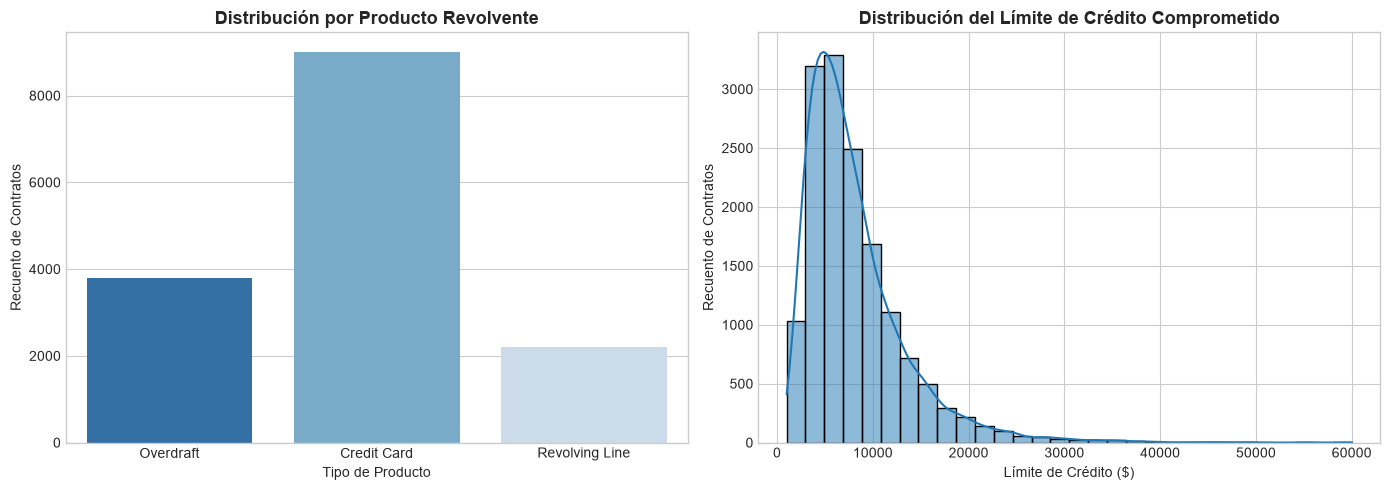

In [5]:
# Composición de Cartera y Distribución de Límites
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tipo de Producto
sns.countplot(data=df_portfolio, x='product_type', palette='Blues_r', ax=axes[0])
axes[0].set_title("Distribución por Producto Revolvente", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Tipo de Producto")
axes[0].set_ylabel("Recuento de Contratos")

# Límite de Crédito
sns.histplot(df_portfolio['credit_limit'], bins=30, kde=True, color='#1f77b4', ax=axes[1])
axes[1].set_title("Distribución del Límite de Crédito Comprometido", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Límite de Crédito ($)")
axes[1].set_ylabel("Recuento de Contratos")

plt.tight_layout()
plt.show()

## Conclusiones y Próximo Paso
* Se formaliza la insuficiencia de datasets públicos genéricos y se establece la estructura adecuada ($B_t, L_t, \text{EAD}_T$).
* **Próximo Cuaderno**: [02_target_construction.ipynb](file:///c:/Users/jhon_/Documents/GitHub/IFRS9-Credit-Risk/CCF/notebooks/02_target_construction.ipynb) formula el cálculo de LEQ y analiza la dinámica de disposición.